# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/AviationData_Cleaned.csv', parse_dates=['Event.Date'])
print(df.shape)
display(df[['Make', 'Model', 'Total.Passengers', 'FatalSerious.Fraction', 'Destroyed']].head())

(57968, 26)


,Make,Model,Total.Passengers,FatalSerious.Fraction,Destroyed
0,CESSNA,182P,4.0,0.0,0
1,CESSNA,182RG,2.0,0.0,0
2,CESSNA,182P,1.0,0.0,0
3,PIPER,PA-28R-200,2.0,0.0,0
4,CESSNA,140,2.0,0.0,0


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
typical_size = df.groupby('Plane')['Total.Passengers'].median()
df['Size'] = np.where(df['Plane'].map(typical_size) >= 20, 'Large', 'Small')

print(df['Size'].value_counts())
print(df.groupby('Size')['Plane'].nunique().rename('plane types'))
large = df[df['Size'] == 'Large']
small = df[df['Size'] == 'Small']

# Minimum number of accident records a make needs before we trust its average
MIN_SMALL, MIN_LARGE = 30, 10
def make_table(d, min_n):
    t = d.groupby('Make').agg(n=('Event.Id', 'count'),
                              mean_fs=('FatalSerious.Fraction', 'mean'),
                              se=('FatalSerious.Fraction', 'sem'),
                              destroyed=('Destroyed', 'mean'))
    return t[t['n'] >= min_n]
small_makes = make_table(small, MIN_SMALL)
large_makes = make_table(large, MIN_LARGE)
print(len(small_makes), 'small makes and', len(large_makes), 'large makes pass the sample-size filter')

Size
Small    56688
Large     1280
Name: count, dtype: int64
Size
Large     399
Small    4058
Name: plane types, dtype: int64
55 small makes and 9 large makes pass the sample-size filter


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

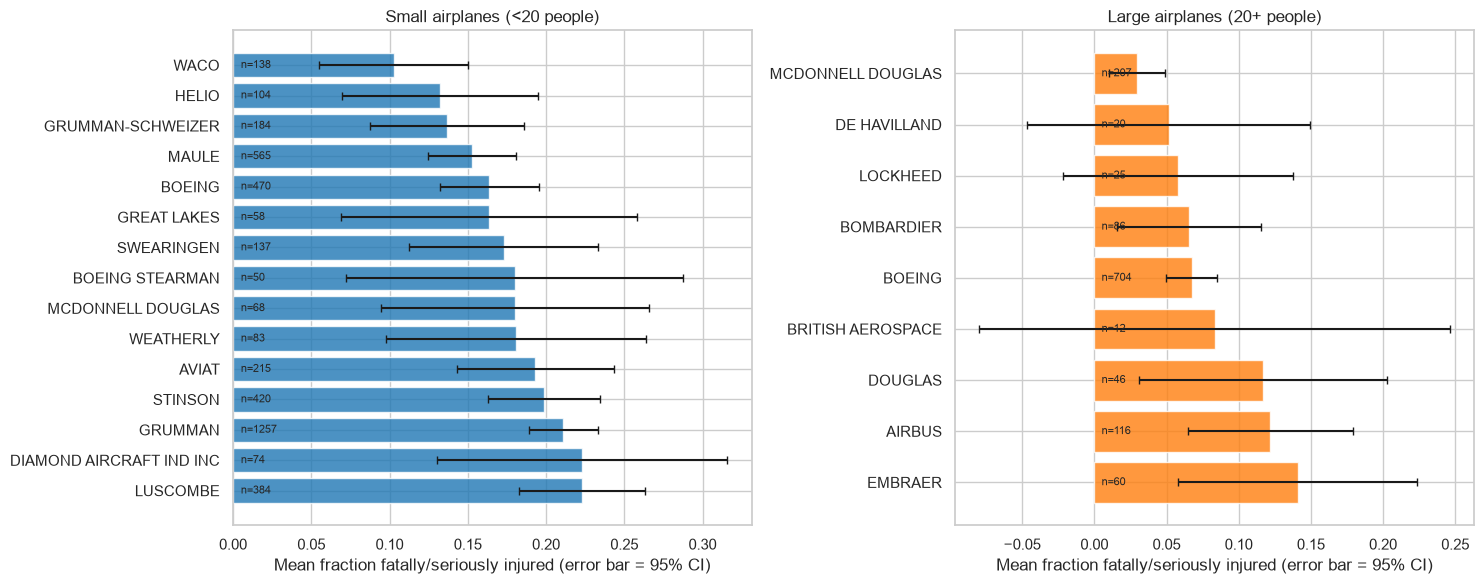

,n,mean_fs,se,destroyed
Make,,,,
WACO,138,0.103,0.024,0.087
HELIO,104,0.132,0.032,0.125
GRUMMAN-SCHWEIZER,184,0.137,0.025,0.179
MAULE,565,0.153,0.014,0.094
BOEING,470,0.164,0.016,0.123
GREAT LAKES,58,0.164,0.048,0.138
SWEARINGEN,137,0.173,0.031,0.175
BOEING STEARMAN,50,0.180,0.055,0.100
MCDONNELL DOUGLAS,68,0.180,0.044,0.221


,n,mean_fs,se,destroyed
Make,,,,
MCDONNELL DOUGLAS,207,0.029,0.010,0.058
DE HAVILLAND,20,0.052,0.050,0.050
LOCKHEED,25,0.058,0.041,0.120
BOMBARDIER,86,0.065,0.025,0.070
BOEING,704,0.067,0.009,0.071
BRITISH AEROSPACE,12,0.083,0.083,0.083
DOUGLAS,46,0.117,0.044,0.087
AIRBUS,116,0.122,0.029,0.129
EMBRAER,60,0.141,0.042,0.133


In [4]:
small_best = small_makes.sort_values('mean_fs').head(15)
large_best = large_makes.sort_values('mean_fs').head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, t, title, c in [(axes[0], small_best, 'Small airplanes (<20 people)', 'tab:blue'),
                        (axes[1], large_best, 'Large airplanes (20+ people)', 'tab:orange')]:
    t = t.iloc[::-1]
    ax.barh(t.index, t['mean_fs'], xerr=1.96 * t['se'], color=c, alpha=.8, capsize=3)
    ax.set_title(title); ax.set_xlabel('Mean fraction fatally/seriously injured (error bar = 95% CI)')
    for y, (n, v) in enumerate(zip(t['n'], t['mean_fs'])):
        ax.text(0.005, y, f'n={n}', va='center', fontsize=8)
plt.tight_layout(); plt.show()
display(small_best.round(3)); display(large_best.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

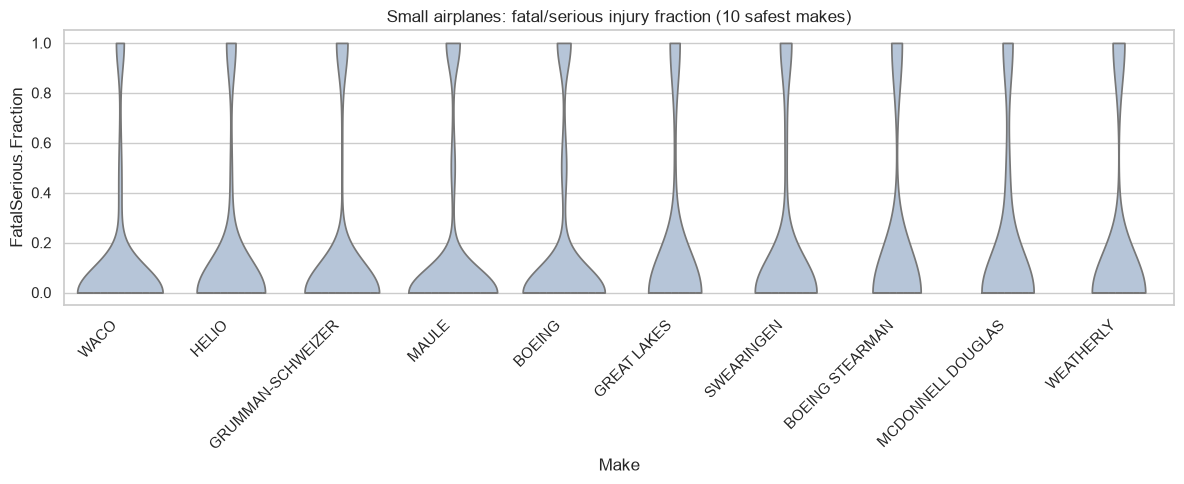

In [5]:
top10_small = small_makes.sort_values('mean_fs').head(10).index
plt.figure(figsize=(12, 5))
sns.violinplot(data=small[small['Make'].isin(top10_small)], x='Make', y='FatalSerious.Fraction',
               order=top10_small, cut=0, inner='quartile', color='lightsteelblue')
plt.xticks(rotation=45, ha='right'); plt.title('Small airplanes: fatal/serious injury fraction (10 safest makes)')
plt.tight_layout(); plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

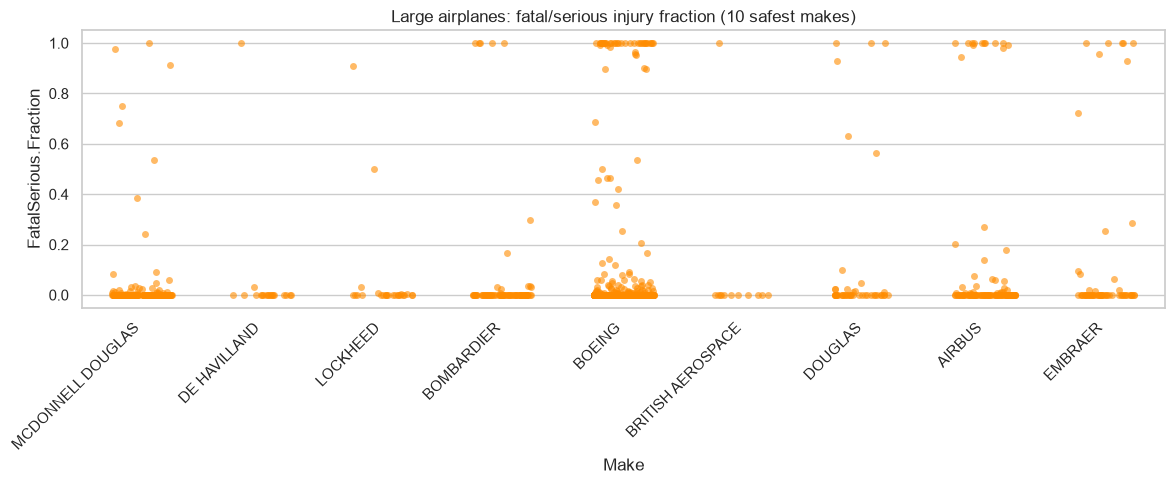

In [6]:
top10_large = large_makes.sort_values('mean_fs').head(10).index
plt.figure(figsize=(12, 5))
sns.stripplot(data=large[large['Make'].isin(top10_large)], x='Make', y='FatalSerious.Fraction',
              order=top10_large, jitter=.25, alpha=.6, color='darkorange')
plt.xticks(rotation=45, ha='right'); plt.title('Large airplanes: fatal/serious injury fraction (10 safest makes)')
plt.tight_layout(); plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

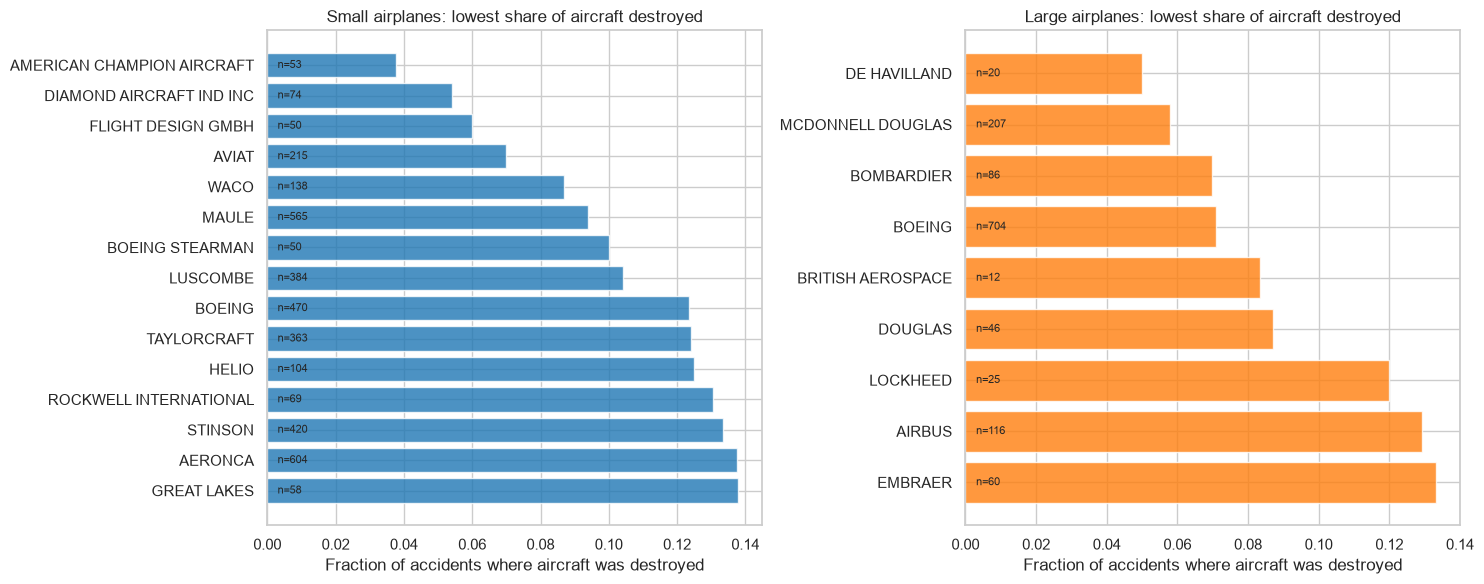

Overall destroyed share - small: 0.209 | large: 0.079


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, t, title, c in [(axes[0], small_makes, 'Small airplanes', 'tab:blue'),
                        (axes[1], large_makes, 'Large airplanes', 'tab:orange')]:
    best = t.sort_values('destroyed').head(15).iloc[::-1]
    ax.barh(best.index, best['destroyed'], color=c, alpha=.8)
    ax.set_title(title + ': lowest share of aircraft destroyed'); ax.set_xlabel('Fraction of accidents where aircraft was destroyed')
    for y, n in enumerate(best['n']): ax.text(0.003, y, f'n={n}', va='center', fontsize=8)
plt.tight_layout(); plt.show()
print('Overall destroyed share - small:', round(small['Destroyed'].mean(), 3), '| large:', round(large['Destroyed'].mean(), 3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [8]:
"""
DISCUSSION: MAKES
Method: makes are ranked only if they have at least 30 events (small planes) or 10 events
(large planes), and every bar shows a 95% confidence interval. Only 9 large makes pass this
filter, so all 9 are shown. Recommendations additionally require at least 50 events.

LARGE AIRPLANES
- McDonnell Douglas has the lowest fatal/serious injury rate (about 3%, 207 events) and a
  destroyed rate of about 6%.
- Bombardier (6.5%, 86 events) and Boeing (6.7%, 704 events) follow, each with a destroyed
  rate of about 7%. Boeing has the most data, so its estimate is the most reliable.
- De Havilland (5%, 20 events) and Lockheed (6%, 25 events) also look good, but their samples
  are small and their confidence intervals wide, so they are promising rather than proven.
- Airbus (12%) and Embraer (14%) have higher injury rates, and both are destroyed in about
  13% of accidents.
- The strip plot shows that most accidents cause no serious injury. The averages are lifted
  by a few catastrophic crashes in which nearly everyone on board is lost.

SMALL AIRPLANES
- Lowest injury rates: Waco (10%), Helio (13%) and Grumman-Schweizer (14%). Maule (15%,
  565 events) is next and has the largest sample of the group.
- Lowest destruction rates: Diamond (5%) and Aviat (7%), against about 21% for all small planes.
  Some makes with very low destruction rates, such as American Champion and Flight Design,
  have high injury rates (28% and 37%), so they are not recommended on safety overall.
- The violin plots show two peaks: a large one at 0 (no serious injuries) and a smaller one at
  1 (everyone on board lost). A mean alone hides this shape.

RECOMMENDATION
- Large: McDonnell Douglas, Bombardier, Boeing.
- Small: Waco, Helio, Grumman-Schweizer (lowest injury); Diamond and Aviat (lowest destruction).
"""

'\nDISCUSSION: MAKES\nMethod: makes are ranked only if they have at least 30 events (small planes) or 10 events\n(large planes), and every bar shows a 95% confidence interval. Only 9 large makes pass this\nfilter, so all 9 are shown. Recommendations additionally require at least 50 events.\n\nLARGE AIRPLANES\n- McDonnell Douglas has the lowest fatal/serious injury rate (about 3%, 207 events) and a\n  destroyed rate of about 6%.\n- Bombardier (6.5%, 86 events) and Boeing (6.7%, 704 events) follow, each with a destroyed\n  rate of about 7%. Boeing has the most data, so its estimate is the most reliable.\n- De Havilland (5%, 20 events) and Lockheed (6%, 25 events) also look good, but their samples\n  are small and their confidence intervals wide, so they are promising rather than proven.\n- Airbus (12%) and Embraer (14%) have higher injury rates, and both are destroyed in about\n  13% of accidents.\n- The strip plot shows that most accidents cause no serious injury. The averages are lifte

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

27 large plane types have >= 10 events


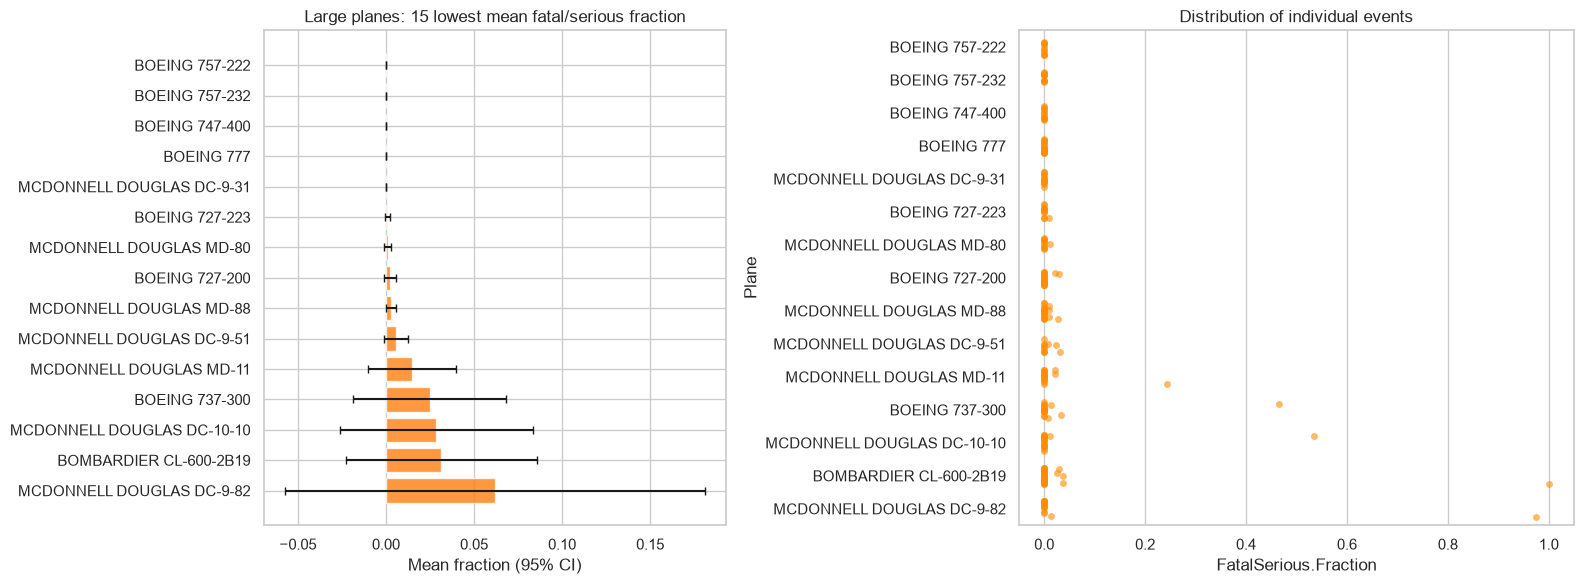

,n,mean_fs,se,destroyed
Plane,,,,
BOEING 757-222,10,0.000,0.000,0.000
BOEING 757-232,10,0.000,0.000,0.000
BOEING 747-400,12,0.000,0.000,0.000
BOEING 777,21,0.000,0.000,0.048
MCDONNELL DOUGLAS DC-9-31,13,0.000,0.000,0.000
BOEING 727-223,11,0.001,0.001,0.000
MCDONNELL DOUGLAS MD-80,11,0.001,0.001,0.000
BOEING 727-200,21,0.002,0.002,0.000
MCDONNELL DOUGLAS MD-88,20,0.003,0.002,0.000


In [9]:
# Plane types with at least 10 recorded events so the average is meaningful
def plane_table(d, n_min=10):
    t = d.groupby('Plane').agg(n=('Event.Id', 'count'), mean_fs=('FatalSerious.Fraction', 'mean'),
                               se=('FatalSerious.Fraction', 'sem'), destroyed=('Destroyed', 'mean'))
    return t[t['n'] >= n_min]

large_planes = plane_table(large)
best_large = large_planes.sort_values('mean_fs').head(15)
print(len(large_planes), 'large plane types have >= 10 events')

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.2]})
t = best_large.iloc[::-1]
ax[0].barh(t.index, t['mean_fs'], xerr=1.96 * t['se'], color='tab:orange', alpha=.8, capsize=3)
ax[0].set_title('Large planes: 15 lowest mean fatal/serious fraction'); ax[0].set_xlabel('Mean fraction (95% CI)')
sns.stripplot(data=large[large['Plane'].isin(best_large.index)], y='Plane', x='FatalSerious.Fraction',
              order=best_large.index, jitter=.25, alpha=.6, color='darkorange', ax=ax[1])
ax[1].set_title('Distribution of individual events')
plt.tight_layout(); plt.show()
display(best_large.round(3))

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

715 small plane types have >= 10 events


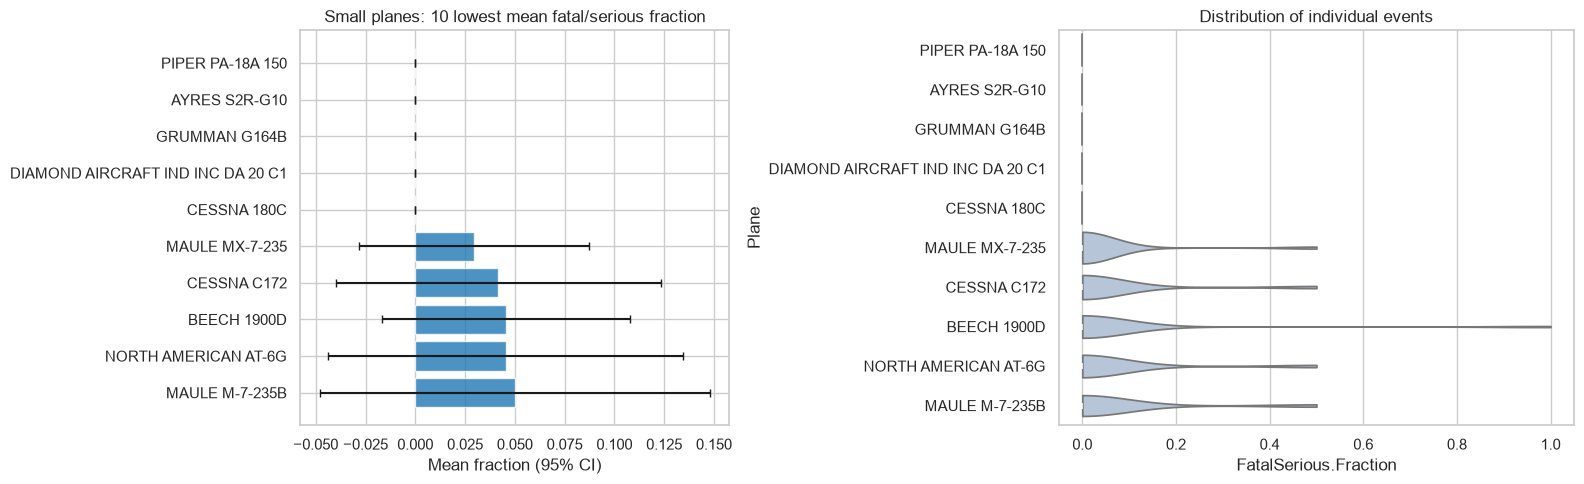

,n,mean_fs,se,destroyed
Plane,,,,
PIPER PA-18A 150,12,0.000,0.000,0.000
AYRES S2R-G10,12,0.000,0.000,0.167
GRUMMAN G164B,16,0.000,0.000,0.062
DIAMOND AIRCRAFT IND INC DA 20 C1,11,0.000,0.000,0.000
CESSNA 180C,15,0.000,0.000,0.067
MAULE MX-7-235,17,0.029,0.029,0.000
CESSNA C172,12,0.042,0.042,0.000
BEECH 1900D,43,0.045,0.032,0.047
NORTH AMERICAN AT-6G,11,0.045,0.045,0.000


In [10]:
small_planes = plane_table(small)
best_small = small_planes.sort_values('mean_fs').head(10)
print(len(small_planes), 'small plane types have >= 10 events')

fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.2]})
t = best_small.iloc[::-1]
ax[0].barh(t.index, t['mean_fs'], xerr=1.96 * t['se'], color='tab:blue', alpha=.8, capsize=3)
ax[0].set_title('Small planes: 10 lowest mean fatal/serious fraction'); ax[0].set_xlabel('Mean fraction (95% CI)')
sns.violinplot(data=small[small['Plane'].isin(best_small.index)], y='Plane', x='FatalSerious.Fraction',
               order=best_small.index, cut=0, color='lightsteelblue', ax=ax[1])
ax[1].set_title('Distribution of individual events')
plt.tight_layout(); plt.show()
display(best_small.round(3))

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [11]:
"""
DISCUSSION: SPECIFIC AIRPLANE TYPES
(Only plane types with at least 10 recorded events are included.)

LARGE AIRPLANES
- Lowest injury rates (about 0%): Boeing 757-222, 757-232, 747-400, 777 and 727 variants,
  and McDonnell Douglas DC-9-31, MD-80 and MD-88.
- Lowest destruction: the Boeing 757s and 747-400 had no destroyed aircraft; the 777 had about 5%.
- Reliability: each type has only 10-36 events, so a single catastrophic crash would raise its
  average sharply (see the MD-11, 737-300, DC-10-10 and CL-600 points between 0.25 and 1.0).
  A mean of 0% from 10 events is encouraging, but it is not proof.
- Recommendation: favor types with more evidence and low injury rates: Boeing 737-300 and
  727-200, McDonnell Douglas MD-88, and Bombardier CL-600-2B19.

SMALL AIRPLANES
- Lowest injury rates (about 0-4%): Piper PA-18A, Cessna 180C, Grumman G164B, Diamond DA-20,
  Ayres S2R, Maule MX-7 and Cessna 172.
- Reliability: these averages rest on only 11-17 events each, so their confidence intervals are wide.
- Most dependable result: the Beech 1900D (43 events, about 4.5% injured). It is a commuter
  turboprop with the largest sample in the list.
- Recommendation: treat the 0% types as promising, and rely on the Beech 1900D as the
  best-supported choice.
"""

'\nDISCUSSION: SPECIFIC AIRPLANE TYPES\n(Only plane types with at least 10 recorded events are included.)\n\nLARGE AIRPLANES\n- Lowest injury rates (about 0%): Boeing 757-222, 757-232, 747-400, 777 and 727 variants,\n  and McDonnell Douglas DC-9-31, MD-80 and MD-88.\n- Lowest destruction: the Boeing 757s and 747-400 had no destroyed aircraft; the 777 had about 5%.\n- Reliability: each type has only 10-36 events, so a single catastrophic crash would raise its\n  average sharply (see the MD-11, 737-300, DC-10-10 and CL-600 points between 0.25 and 1.0).\n  A mean of 0% from 10 events is encouraging, but it is not proof.\n- Recommendation: favor types with more evidence and low injury rates: Boeing 737-300 and\n  727-200, McDonnell Douglas MD-88, and Bombardier CL-600-2B19.\n\nSMALL AIRPLANES\n- Lowest injury rates (about 0-4%): Piper PA-18A, Cessna 180C, Grumman G164B, Diamond DA-20,\n  Ayres S2R, Maule MX-7 and Cessna 172.\n- Reliability: these averages rest on only 11-17 events each, so

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,n,fatal_serious,destroyed
Weather.Condition,,,
IMC,4615,0.661,0.580
VMC,51240,0.219,0.166


,n,fatal_serious,destroyed
Number.of.Engines,,,
1.0,48029,0.250,0.189
2.0,7229,0.353,0.320


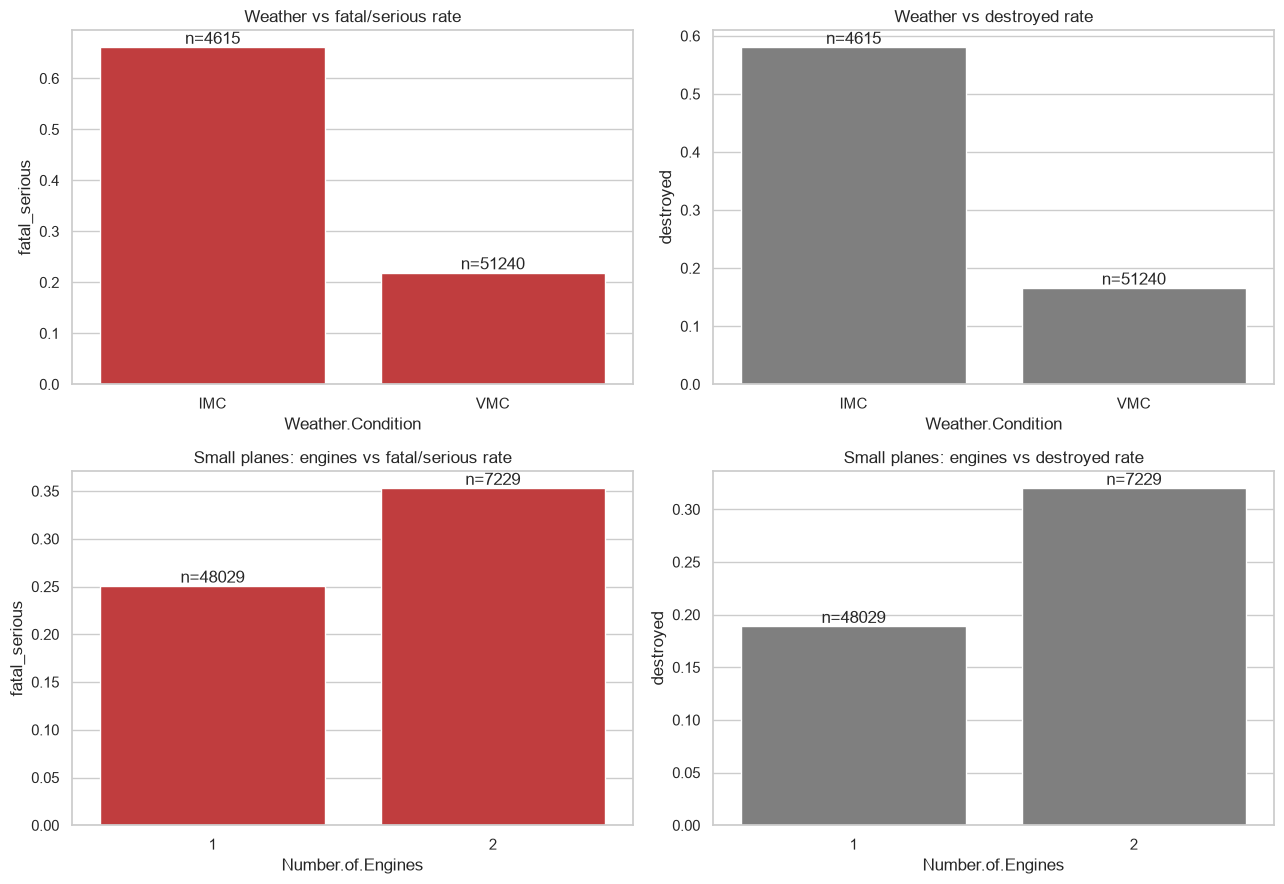

Weather VMC vs IMC: fatal/serious t-test p=0.00e+00 | destroyed chi-square p=0.00e+00
Small planes: 1 vs 2 engines: fatal/serious t-test p=3.73e-69 | destroyed chi-square p=1.81e-145


In [12]:
# FACTOR 1: Weather condition (VMC = good visibility, IMC = poor visibility)
# FACTOR 2: Number of engines (small planes: 1 vs 2 engines)
from scipy import stats

def summarise(d, col):
    g = d.groupby(col).agg(n=('Event.Id', 'count'),
                           fatal_serious=('FatalSerious.Fraction', 'mean'),
                           destroyed=('Destroyed', 'mean'))
    return g[g['n'] >= 30]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
# --- weather ---
w = summarise(df[df['Weather.Condition'].isin(['VMC', 'IMC'])], 'Weather.Condition')
display(w.round(3))
for ax, m, c in zip(axes[0], ['fatal_serious', 'destroyed'], ['tab:red', 'tab:gray']):
    sns.barplot(x=w.index, y=w[m], color=c, ax=ax); ax.set_title(f'Weather vs {m.replace("_", "/")} rate')
    for i, n in enumerate(w['n']): ax.text(i, w[m].iloc[i], f'n={n}', ha='center', va='bottom')
# --- engines ---
e = df[(df['Size'] == 'Small') & df['Number.of.Engines'].isin([1, 2])]
eg = summarise(e, 'Number.of.Engines')
display(eg.round(3))
for ax, m, c in zip(axes[1], ['fatal_serious', 'destroyed'], ['tab:red', 'tab:gray']):
    sns.barplot(x=eg.index.astype(int), y=eg[m], color=c, ax=ax); ax.set_title(f'Small planes: engines vs {m.replace("_", "/")} rate')
    for i, n in enumerate(eg['n']): ax.text(i, eg[m].iloc[i], f'n={n}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

# Are the differences statistically significant?  (Welch t-test on fraction, chi-square on destroyed)
for name, d, col, a, b in [('Weather VMC vs IMC', df, 'Weather.Condition', 'VMC', 'IMC'),
                           ('Small planes: 1 vs 2 engines', e, 'Number.of.Engines', 1, 2)]:
    x, y = d[d[col] == a], d[d[col] == b]
    t = stats.ttest_ind(x['FatalSerious.Fraction'], y['FatalSerious.Fraction'], equal_var=False)
    chi = stats.chi2_contingency(pd.crosstab(d[d[col].isin([a, b])][col], d[d[col].isin([a, b])]['Destroyed']))
    print(f'{name}: fatal/serious t-test p={t.pvalue:.2e} | destroyed chi-square p={chi[1]:.2e}')